# Bài kiểm tra 2 · Huấn luyện và đánh giá

So sánh baseline dự đoán trung bình log giá, Linear Regression, Ridge, Lasso và Elastic Net. Dùng đúng train/test đã chốt ở KT1. Không tự chạy lại tìm kiếm khi mở notebook này; số liệu được đọc từ lần thực nghiệm đã lưu. Toàn bộ lệnh huấn luyện nằm ở `src/experiments.py`, tái tạo bằng `python -m src.experiments`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import Image, display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
DATA=ROOT/'reports/experiments'
assert (DATA/'results.json').exists(), 'Chạy python -m src.experiments trước'
result=json.loads((DATA/'results.json').read_text(encoding='utf-8'))
def table(name): return pd.read_csv(DATA/name)
def figure(name): display(Image(filename=str(ROOT/'reports/figures'/name)))


## 1 Lựa chọn thuật toán và baseline

OLS là tham chiếu tuyến tính không phạt. Ridge ổn định hệ số khi đa cộng tuyến. Lasso tạo nghiệm thưa. Elastic Net kết hợp cả hai. Baseline DummyRegressor học mean của log1p giá trên từng train fold, tránh lấy hằng số từ test.

In [2]:
from src.preprocessing import load_raw
from src.experiments import temporal_folds
raw=load_raw(ROOT/'data/raw/AmesHousing.tsv')
train=raw[raw['Yr Sold']<2010].reset_index(drop=True)
for a,b in temporal_folds(train):
    print('Train years:',sorted(train.iloc[a]['Yr Sold'].unique()), 'validation:',train.iloc[b]['Yr Sold'].unique(), 'sizes:',len(a),len(b))

Train years: [np.int64(2006)] validation: [2007] sizes: 625 694
Train years: [np.int64(2006), np.int64(2007)] validation: [2008] sizes: 1319 622
Train years: [np.int64(2006), np.int64(2007), np.int64(2008)] validation: [2009] sizes: 1941 648


## 2 Pipeline đầy đủ và cấu hình KT2

FeatureBuilder tự bỏ nhãn/ID và làm sạch raw; preprocessing clip p99, điền thiếu, chuẩn hóa số, one-hot. TransformedTargetRegressor học log1p và hoàn nguyên expm1. Mỗi fold fit lại toàn bộ. KT2 dùng alpha Ridge=10, Lasso=0.001, Elastic Net=0.001 với l1_ratio=0.5, cố định trước tìm kiếm KT3.

In [3]:
from sklearn.linear_model import Ridge
from src.modeling import make_model
display(make_model(train,Ridge(alpha=10)))

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...e(alpha=10))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,engineered,False
,log_areas,False


## 3 Kết quả kiểm định

RMSE log là chỉ số chính, mean/std mẫu qua 3 năm kiểm định. Các cột train cho thấy chênh lệch mức khớp. Thời gian phụ thuộc máy; không dùng để khẳng định chênh lệch tốc độ tuyệt đối.

,model,cv_rmse_log_mean,cv_rmse_log_std,cv_train_rmse_log_mean,cv_mae_usd_mean,cv_rmse_usd_mean,cv_r2_usd_mean,fit_seconds_mean
0,DummyMeanLog,0.404647,0.011984,0.405639,56380.639767,80913.520270,-0.032778,0.246781
1,LinearRegression,0.143351,0.017889,0.077947,16219.925676,32253.421848,0.823780,0.236684
2,Ridge_default,0.127720,0.007501,0.088760,14576.518516,26988.481159,0.881015,0.227575
3,Lasso_default,0.128952,0.009852,0.100333,14600.584869,27315.771810,0.877522,0.263735
4,ElasticNet_default,0.127485,0.009612,0.093600,14457.973176,26738.356067,0.882911,0.278732


,model,fold,validation_year,n_train,n_validation,fit_seconds,train_rmse_log,train_mae_usd,train_rmse_usd,train_r2_usd,rmse_log,mae_usd,rmse_usd,r2_usd
0,DummyMeanLog,1,2007,625,694,0.222827,0.412357,57727.001302,83948.827133,-0.034088,0.391281,56860.482300,84558.475752,-0.050951
1,DummyMeanLog,2,2008,1319,622,0.221819,0.401180,57397.727125,83843.443056,-0.031987,0.408227,55212.489235,76199.554173,-0.017756
2,DummyMeanLog,3,2009,1941,648,0.295696,0.403380,56611.842567,81689.984763,-0.032696,0.414433,57068.947765,81982.530886,-0.029628
3,LinearRegression,1,2007,625,694,0.192237,0.066980,8236.628550,11603.351045,0.980244,0.152575,18957.062240,39154.045732,0.774669
4,LinearRegression,2,2008,1319,622,0.237223,0.080776,10324.373256,15236.115435,0.965921,0.154745,15849.238951,36744.389448,0.763342
5,LinearRegression,3,2009,1941,648,0.280592,0.086086,10859.620090,16552.917448,0.957598,0.122732,13853.475839,20861.830363,0.933328
6,Ridge_default,1,2007,625,694,0.194018,0.079746,10078.799559,14489.256793,0.969195,0.127977,15894.381005,32472.678026,0.845010
7,Ridge_default,2,2008,1319,622,0.223369,0.090041,11459.818970,17952.244209,0.952688,0.135090,13721.247717,28058.611138,0.862003
8,Ridge_default,3,2009,1941,648,0.265338,0.096492,11880.213660,19240.093091,0.942714,0.120094,14113.926826,20434.154313,0.936034
9,Lasso_default,1,2007,625,694,0.245560,0.089589,11290.383290,16492.060819,0.960090,0.129150,16041.520585,33486.528050,0.835181


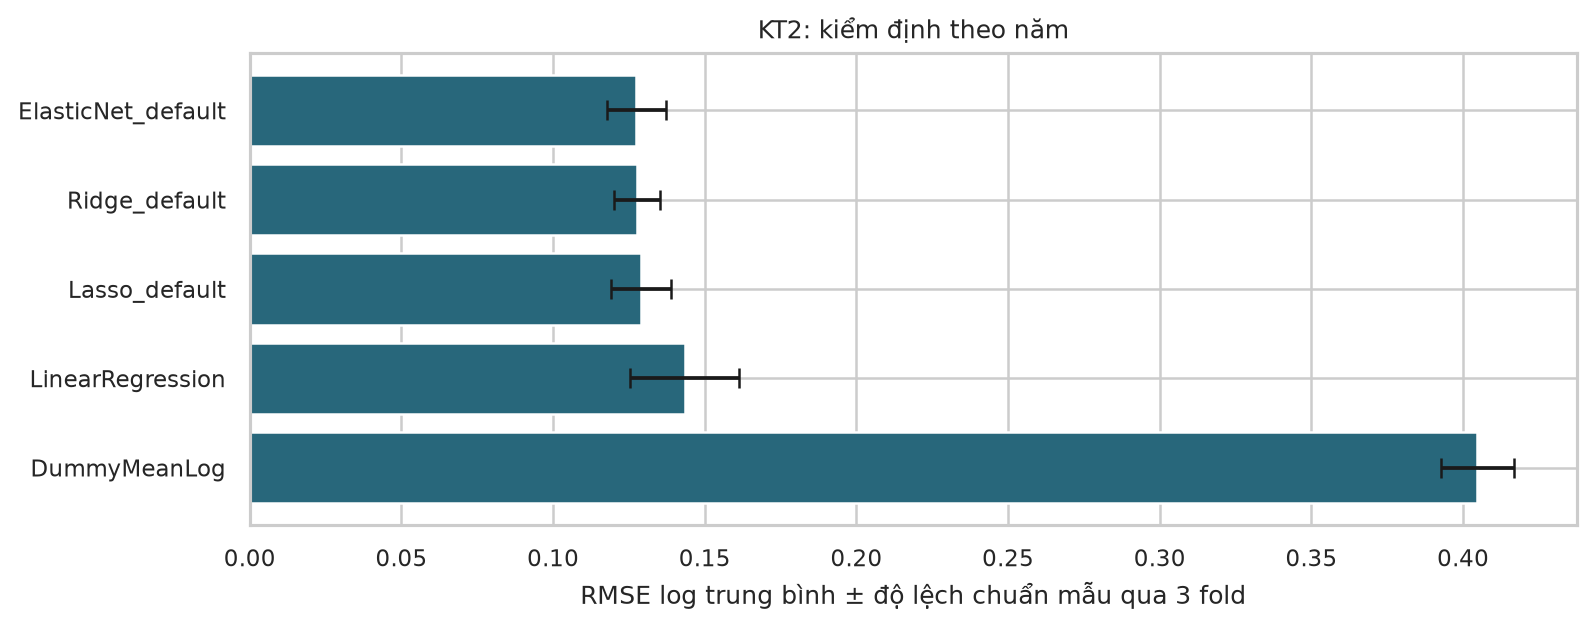

In [4]:
display(table('kt2_cv_summary.csv'))
display(table('all_cv_folds.csv').query('model in ["DummyMeanLog","LinearRegression","Ridge_default","Lasso_default","ElasticNet_default"]'))
figure('09_kt2_cv.png')

OLS có khoảng cách train–validation lớn hơn các mô hình chính quy hóa. Ridge/Lasso/Elastic Net đều vượt baseline rõ rệt trên CV. Elastic Net cấu hình ban đầu có RMSE log trung bình tốt nhất trong KT2, nhưng chênh lệch với Ridge rất nhỏ so với biến động giữa năm. Chưa thể nói mô hình đó ưu thế chắc chắn.

## 4 Kết quả test đã khóa sau KT3

Để giữ test độc lập, bảng test KT2 được tính sau khi toàn bộ lựa chọn KT3 đã khóa. Không dùng bảng này để đổi alpha hoặc chọn lại mô hình cuối.

,model,fit_full_seconds,train_rmse_log,train_mae_usd,train_rmse_usd,train_r2_usd,rmse_log,mae_usd,rmse_usd,r2_usd
0,DummyMeanLog,0.240284,0.406171,56708.439999,81815.091671,-0.033218,0.417947,53059.844185,74716.702081,-0.005234
1,LinearRegression,0.290151,0.092741,11368.611152,17166.159824,0.954515,0.171491,15093.201089,22063.320914,0.912346
2,Ridge_default,0.268614,0.100722,12066.182086,19172.292116,0.943262,0.149412,14677.763181,21204.881359,0.919034
3,Lasso_default,0.327080,0.113001,13284.735935,22317.100028,0.923122,0.151697,14947.526512,21948.084882,0.913259
4,ElasticNet_default,0.868663,0.108148,12701.295370,21285.463096,0.930066,0.149169,14804.832501,21455.326221,0.917110


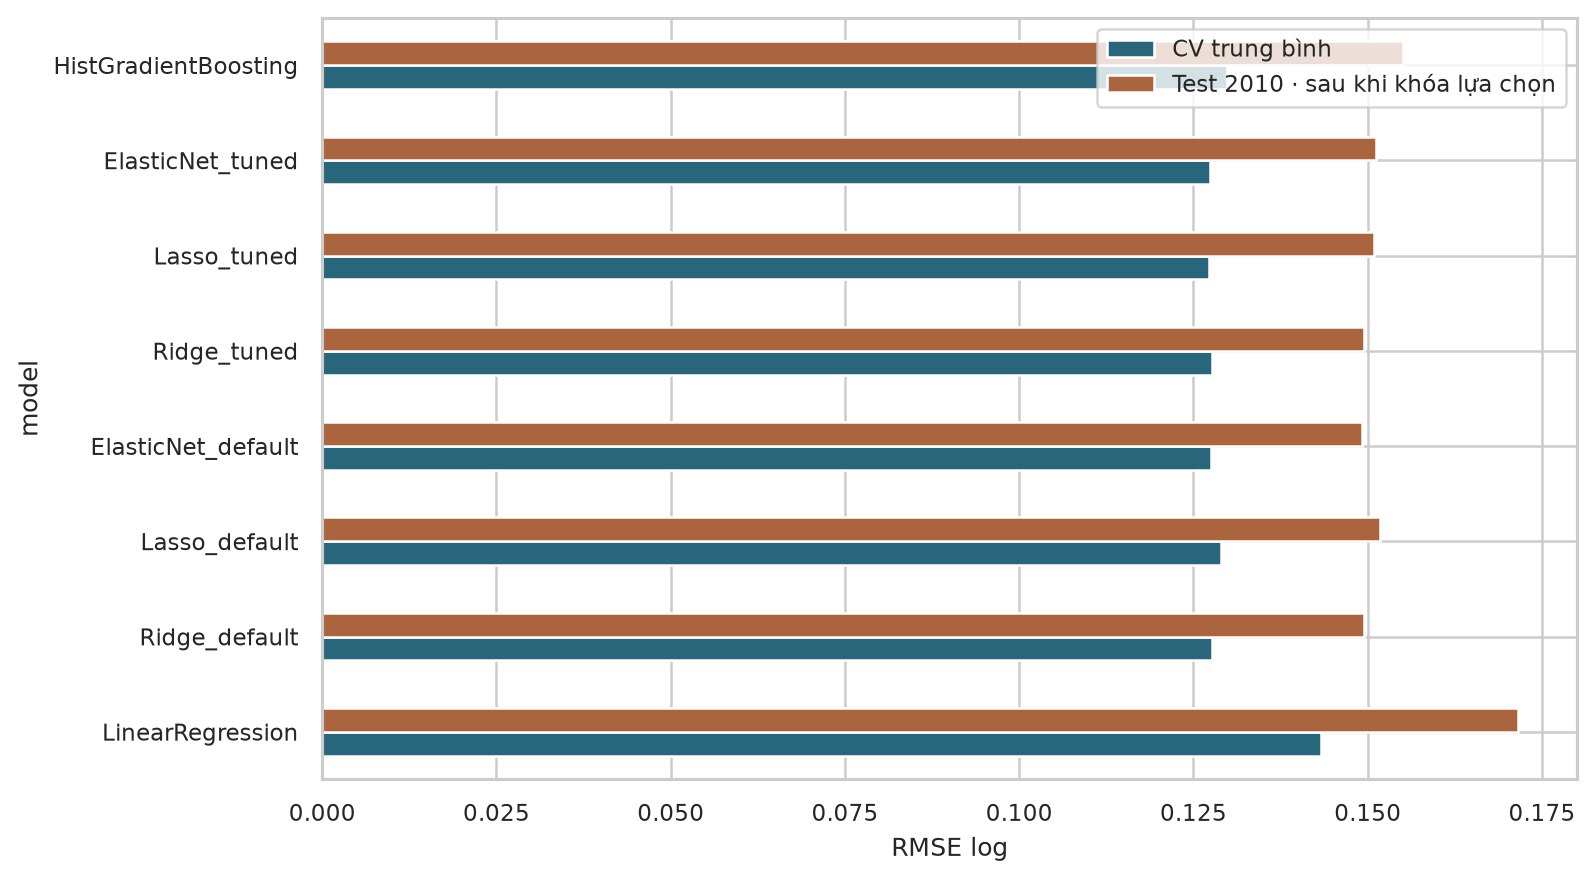

In [5]:
display(table('final_test_comparison.csv').query('model in ["DummyMeanLog","LinearRegression","Ridge_default","Lasso_default","ElasticNet_default"]'))
figure('16_cv_vs_test.png')

## 5 Phân tích lỗi và giải thích

Phân tích phần dư mô hình cuối được dùng cho cả KT2/KT3; các lỗi này chỉ được mô tả sau khi lựa chọn đã khóa. Nhóm nhà giá cao có MAE USD lớn hơn; sai số tuyệt đối tăng theo thang giá là lý do cần báo cáo cả log và USD.

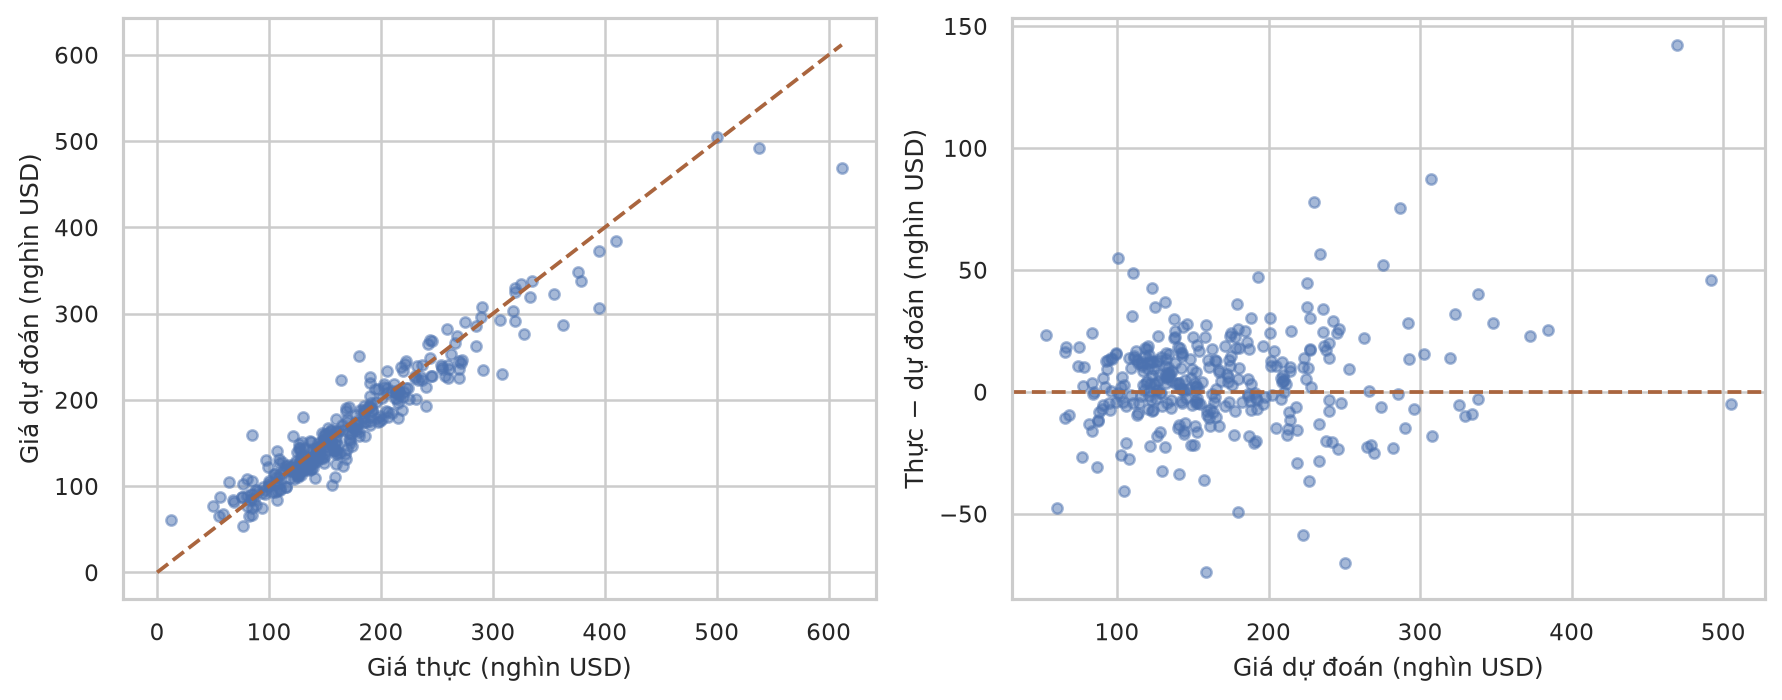

,price_band,n,mae_usd,mean_abs_log_error
0,<150k,159,11161.717745,0.108364
1,150k-250k,140,14835.732030,0.081906
2,>250k,42,28781.400397,0.092616


,Order,PID,Gr Liv Area,Overall Qual,Neighborhood,SalePrice,prediction_usd,residual_usd,absolute_error_usd,absolute_log_error,price_band
0,45,528150070,2364,9,NridgHt,611657,469324.806550,142332.193450,142332.193450,0.264876,>250k
1,18,527258010,1856,9,StoneBr,394432,306964.243459,87467.756541,87467.756541,0.250715,>250k
2,242,905453080,1508,7,Edwards,308030,230074.909076,77955.090924,77955.090924,0.291791,>250k
3,92,533130130,2349,8,NoRidge,362500,287012.564837,75487.435163,75487.435163,0.233498,>250k
4,126,534427010,1728,5,NAmes,84900,158982.584756,-74082.584756,74082.584756,0.627315,<150k
5,137,535125010,2207,7,NAmes,180000,250410.926448,-70410.926448,70410.926448,0.330145,150k-250k
6,17,527225035,1752,8,Gilbert,164000,222862.210689,-58862.210689,58862.210689,0.306686,150k-250k
7,40,528120090,1544,8,NridgHt,290941,234264.033794,56676.966206,56676.966206,0.216671,>250k


In [6]:
figure('11_predictions_residuals.png')
display(table('errors_by_price_band.csv'))
display(table('largest_errors.csv').head(8))

## 6 Thực hành cá nhân

Thử một thay đổi trên CV, không đụng test: đổi alpha, đổi chỉ số sang MAE, hoặc thay Ridge bằng Lasso. Ô dưới chỉ chạy một fold với dữ liệu train, dùng để thực hành tại chỗ.

In [7]:
from sklearn.base import clone
from src.experiments import metrics
from src.modeling import predict_nonnegative
a,b=temporal_folds(train)[0]
demo=make_model(train,Ridge(alpha=30))
demo.fit(train.iloc[a],train.iloc[a].SalePrice)
print(metrics(train.iloc[b].SalePrice,predict_nonnegative(demo,train.iloc[b])))

{'rmse_log': 0.12790945586328517, 'mae_usd': 15937.764475368072, 'rmse_usd': 33077.81082714937, 'r2_usd': 0.8391794187657204}


Đọc `docs/ON_TAP_KT2_KT3.md` để giải thích hàm mục tiêu, tham số và các cột kết quả. AI hỗ trợ xây dựng mã/tài liệu; sinh viên tự kiểm tra, hiểu và ghi nhận phần việc thực tế trước khi nộp.